# Modelado Predictivo — Dengue CON Signos de Alarma (DCSA)
## DCSA · 12,713 casos · 64.8% hospitalizados

---

El objetivo es predecir, al momento de la consulta, si un paciente
con dengue con signos de alarma requiere hospitalización.

**Estructura del notebook:**
1. Setup y carga de datos
2. Preparación de features y partición
3. Baselines (Dummy + Decision Tree) — referencia mínima
4. Portafolio completo con validación cruzada 5-fold
5. Evaluación final en test set (una única vez)
6. Importancia de variables

**Métrica primaria:** F1-score — el desbalance 65/35 es moderado,
F1 equilibra precisión y sensibilidad adecuadamente.

**Siguiente:** `03_modelado_sin_signos.ipynb`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import joblib
import importlib
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    f1_score, roc_auc_score, balanced_accuracy_score,
    precision_score, recall_score, average_precision_score,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, make_scorer)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
if importlib.util.find_spec('catboost') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})

COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB',
}
SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita aqui si es necesario
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

df = joblib.load(INTERIM / 'datos_con_signos.pkl')
print(f'DCSA — Dengue con signos de alarma')
print(f'  Casos      : {len(df):,}')
print(f'  Hosp.      : {df[TARGET].mean():.1%}')
print(f'  No hosp.   : {1-df[TARGET].mean():.1%}')

DCSA — Dengue con signos de alarma
  Casos      : 12,713
  Hosp.      : 64.8%
  No hosp.   : 35.2%


In [2]:
import gc

def checkpoint_existe(path):
    """Retorna True si el checkpoint ya fue guardado."""
    return Path(path).exists()

def guardar_checkpoint(obj, path, nombre=''):
    """Guarda objeto y reporta tamanio."""
    joblib.dump(obj, path)
    mb = Path(path).stat().st_size / 1e6
    print(f'  Guardado {nombre}: {path.name} ({mb:.1f} MB)')

def limpiar_memoria(*objetos):
    """Elimina objetos grandes de memoria y fuerza garbage collection."""
    for obj in objetos:
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    print('  Memoria liberada')

def memoria_usada():
    """Muestra uso de RAM actual."""
    import psutil, os
    proc = psutil.Process(os.getpid())
    mb   = proc.memory_info().rss / 1e6
    print(f'  RAM en uso: {mb:.0f} MB')

# Instalar psutil si no esta disponible
try:
    import psutil
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'psutil'])
    import psutil

print('Utilidades listas: checkpoint_existe / guardar_checkpoint / limpiar_memoria / memoria_usada')

Utilidades listas: checkpoint_existe / guardar_checkpoint / limpiar_memoria / memoria_usada


## 1. Preparación de features y partición

In [ ]:
vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']
                 if v in df.columns]
# AÑO excluido: es variable de control de sesgo temporal, no predictor clinico.
# Un modelo desplegable en clinica no tiene acceso al año como predictor.
# Solo se mantiene SEMANA como proxy de estacionalidad epidemiologica.
vars_tiempo   = [v for v in ['SEMANA'] if v in df.columns]
FEATURES      = vars_clinicas + vars_demo + vars_tiempo

CP_PARTICION = CHECKPOINTS / 'particion_DCSA.pkl'

if checkpoint_existe(CP_PARTICION):
    print('Cargando particion desde checkpoint...')
    X_train, X_test, y_train, y_test, FEATURES = joblib.load(CP_PARTICION)
    vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo     = [v for v in FEATURES if v not in vars_clinicas + ['SEMANA']]
    vars_tiempo   = [v for v in FEATURES if v in ['SEMANA']]
else:
    print('Preparando datos...')
    df_m = df[FEATURES + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in FEATURES:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)
    df_m = df_m.dropna(subset=[TARGET])
    X    = df_m[FEATURES]
    y    = df_m[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    guardar_checkpoint((X_train, X_test, y_train, y_test, FEATURES),
        CP_PARTICION, 'particion DCSA')
    limpiar_memoria(df_m, X, y)

print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'Prev. train: {y_train.mean():.1%} | test: {y_test.mean():.1%}')
memoria_usada()

In [ ]:
# Preprocesador
# Numericas (demo + semana): mediana + estandarizacion
# Binarias (clinicas): moda, sin escala
# AÑO excluido del modelo — ver justificacion en celda anterior
cols_numericas = vars_demo + vars_tiempo  # vars_tiempo = ['SEMANA'] o []

preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc',  StandardScaler())
    ]), cols_numericas),
    ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas),
], remainder='drop')

def make_pipe(clf, smote=True):
    pasos = [('prep', preprocesador)]
    if smote:
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    pasos.append(('clf', clf))
    return ImbPipeline(pasos)

print(f'Preprocesador listo')
print(f'  Numericas : {cols_numericas}')
print(f'  Binarias  : {vars_clinicas}')

## 2. Baselines — referencia mínima

Todo modelo avanzado debe superar al Decision Tree en F1
para justificar su complejidad computacional e interpretativa.

  Guardado baselines: baseline_DCSA.pkl (0.0 MB)

=== Dummy ===
               precision    recall  f1-score   support

     No hosp.       0.00      0.00      0.00       894
Hospitalizado       0.65      1.00      0.79      1649

     accuracy                           0.65      2543
    macro avg       0.32      0.50      0.39      2543
 weighted avg       0.42      0.65      0.51      2543


=== Decision Tree depth=3 ===
               precision    recall  f1-score   support

     No hosp.       0.63      0.81      0.71       894
Hospitalizado       0.88      0.74      0.80      1649

     accuracy                           0.76      2543
    macro avg       0.75      0.77      0.75      2543
 weighted avg       0.79      0.76      0.77      2543



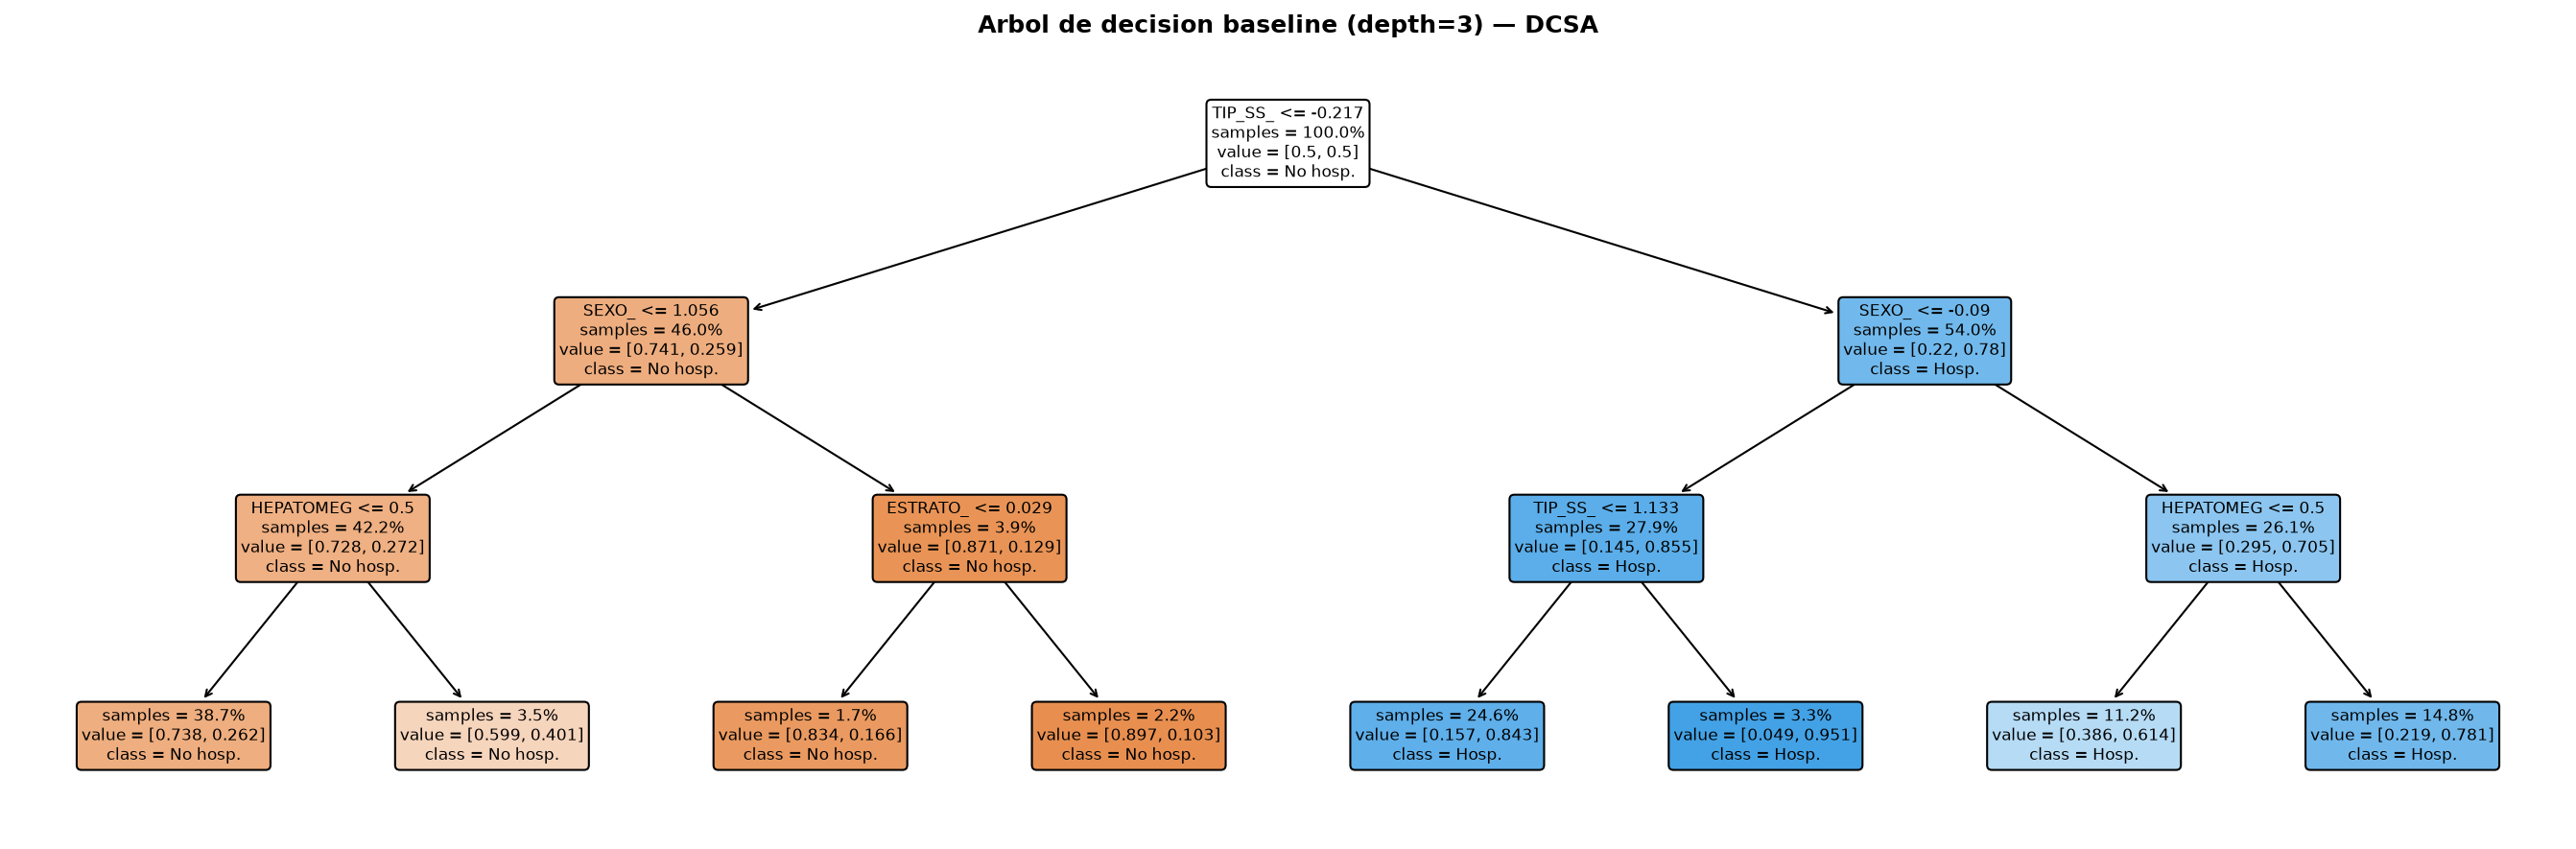

  Memoria liberada
  RAM en uso: 307 MB


In [5]:
CP_BASELINE = CHECKPOINTS / 'baseline_DCSA.pkl'

if checkpoint_existe(CP_BASELINE):
    print('Baselines ya entrenados — cargando checkpoint...')
    dummy, dt = joblib.load(CP_BASELINE)
else:
    dummy = make_pipe(DummyClassifier(strategy='most_frequent'), smote=False)
    dt    = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=50,
        class_weight='balanced', random_state=RANDOM_STATE), smote=False)
    dummy.fit(X_train, y_train)
    dt.fit(X_train, y_train)
    guardar_checkpoint((dummy, dt), CP_BASELINE, 'baselines')

for nombre, pipe in [('Dummy', dummy), ('Decision Tree depth=3', dt)]:
    y_pred = pipe.predict(X_test)
    print(f'\n=== {nombre} ===')
    print(classification_report(y_test, y_pred,
        target_names=['No hosp.', 'Hospitalizado']))

feature_names_out = vars_demo + vars_tiempo + vars_clinicas
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(dt.named_steps['clf'], feature_names=feature_names_out,
    class_names=['No hosp.', 'Hosp.'], filled=True, rounded=True,
    fontsize=8, ax=ax, impurity=False, proportion=True)
ax.set_title('Arbol de decision baseline (depth=3) — DCSA', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_baseline_tree.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()
limpiar_memoria()
memoria_usada()

## 3. validación cruzada 5-fold

Se evalúa en CV antes de ver el test set.
Seleccionar el mejor modelo mirando el test set directamente
es optimismo selectivo — sesgo frecuente en IA clínica.

In [6]:
CP_CV = CHECKPOINTS / 'cv_DCSA.pkl'

# n_estimators reducidos en CV para ahorrar memoria
# El modelo final (evaluacion test) usa los parametros completos
# n_jobs=1 en CV evita multiplicar la RAM por numero de cores
portafolio_cv = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=500, C=1.0,
                             random_state=RANDOM_STATE, n_jobs=1)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=100,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=100, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE,
                             thread_count=1, verbose=0)),
}

# Portafolio final con parametros completos — solo para los top 3
portafolio_final = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=1000, C=1.0,
                             random_state=RANDOM_STATE)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=200,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=300, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE,
                             thread_count=1, verbose=0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1':                make_scorer(f1_score, pos_label=1),
    'roc_auc':           make_scorer(roc_auc_score, needs_proba=True),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
    'precision':         make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall':            make_scorer(recall_score, pos_label=1),
    'average_precision': make_scorer(average_precision_score, needs_proba=True),
}

if checkpoint_existe(CP_CV):
    print('CV ya calculada — cargando...')
    resultados_cv = joblib.load(CP_CV)
    for nombre, res in resultados_cv.items():
        print(f"  {nombre}: F1={res['f1']['mean']:.3f} +/- {res['f1']['std']:.3f}")
else:
    resultados_cv = {}
    for nombre, pipe in portafolio_cv.items():
        CP_MOD = CHECKPOINTS / f'cv_DCSA_{nombre.replace(" ","_").replace(".","")}.pkl'
        if checkpoint_existe(CP_MOD):
            print(f'  {nombre}: ya calculado, cargando...')
            resultados_cv[nombre] = joblib.load(CP_MOD)
        else:
            print(f'  Entrenando {nombre}...', end=' ', flush=True)
            # n_jobs=1 en cross_validate: un fold a la vez, RAM controlada
            cv_res = cross_validate(pipe, X_train, y_train,
                cv=cv, scoring=scoring, n_jobs=1)
            resultados_cv[nombre] = {
                m: {'mean': cv_res[f'test_{m}'].mean(),
                    'std':  cv_res[f'test_{m}'].std()}
                for m in scoring
            }
            guardar_checkpoint(resultados_cv[nombre], CP_MOD, nombre)
            print(f"F1={resultados_cv[nombre]['f1']['mean']:.3f}")
        limpiar_memoria()
        memoria_usada()
    guardar_checkpoint(resultados_cv, CP_CV, 'CV completa DCSA')

memoria_usada()

  Entrenando Dummy...   Guardado Dummy: cv_DCSA_Dummy.pkl (0.0 MB)
F1=0.787
  Memoria liberada
  RAM en uso: 309 MB
  Entrenando Decision Tree...   Guardado Decision Tree: cv_DCSA_Decision_Tree.pkl (0.0 MB)
F1=0.788
  Memoria liberada
  RAM en uso: 309 MB
  Entrenando Logistic Reg....   Guardado Logistic Reg.: cv_DCSA_Logistic_Reg.pkl (0.0 MB)
F1=0.789
  Memoria liberada
  RAM en uso: 307 MB
  Entrenando Random Forest...   Guardado Random Forest: cv_DCSA_Random_Forest.pkl (0.0 MB)
F1=0.795
  Memoria liberada
  RAM en uso: 308 MB
  Entrenando Extra Trees...   Guardado Extra Trees: cv_DCSA_Extra_Trees.pkl (0.0 MB)
F1=0.796
  Memoria liberada
  RAM en uso: 308 MB
  Entrenando Gradient Boosting...   Guardado Gradient Boosting: cv_DCSA_Gradient_Boosting.pkl (0.0 MB)
F1=0.794
  Memoria liberada
  RAM en uso: 309 MB
  Entrenando XGBoost...   Guardado XGBoost: cv_DCSA_XGBoost.pkl (0.0 MB)
F1=0.795
  Memoria liberada
  RAM en uso: 310 MB
  Entrenando LightGBM...   Guardado LightGBM: cv_DCSA_Lig

## 4. Tabla y gráfico comparativo

,Modelo,F1,F1_std,AUC_ROC,AUC_PR,Bal_Acc,Precision,Recall
4,Extra Trees,0.7962,0.0073,0.8070,0.8781,0.7585,0.8588,0.7421
3,Random Forest,0.7953,0.0064,0.8118,0.8824,0.7607,0.8629,0.7375
6,XGBoost,0.7949,0.0069,0.8141,0.8840,0.7628,0.8665,0.7342
7,LightGBM,0.7947,0.0072,0.8150,0.8847,0.7618,0.8652,0.7348
5,Gradient Boosting,0.7942,0.0078,0.8117,0.8816,0.7625,0.8667,0.7328
8,CatBoost,0.7933,0.0070,0.8129,0.8829,0.7618,0.8664,0.7316
2,Logistic Reg.,0.7888,0.0081,0.7996,0.8737,0.7599,0.8678,0.7231
1,Decision Tree,0.7877,0.0072,0.7908,0.8442,0.7588,0.8672,0.7216
0,Dummy,0.7868,0.0000,0.5000,0.6485,0.5000,0.6485,1.0000


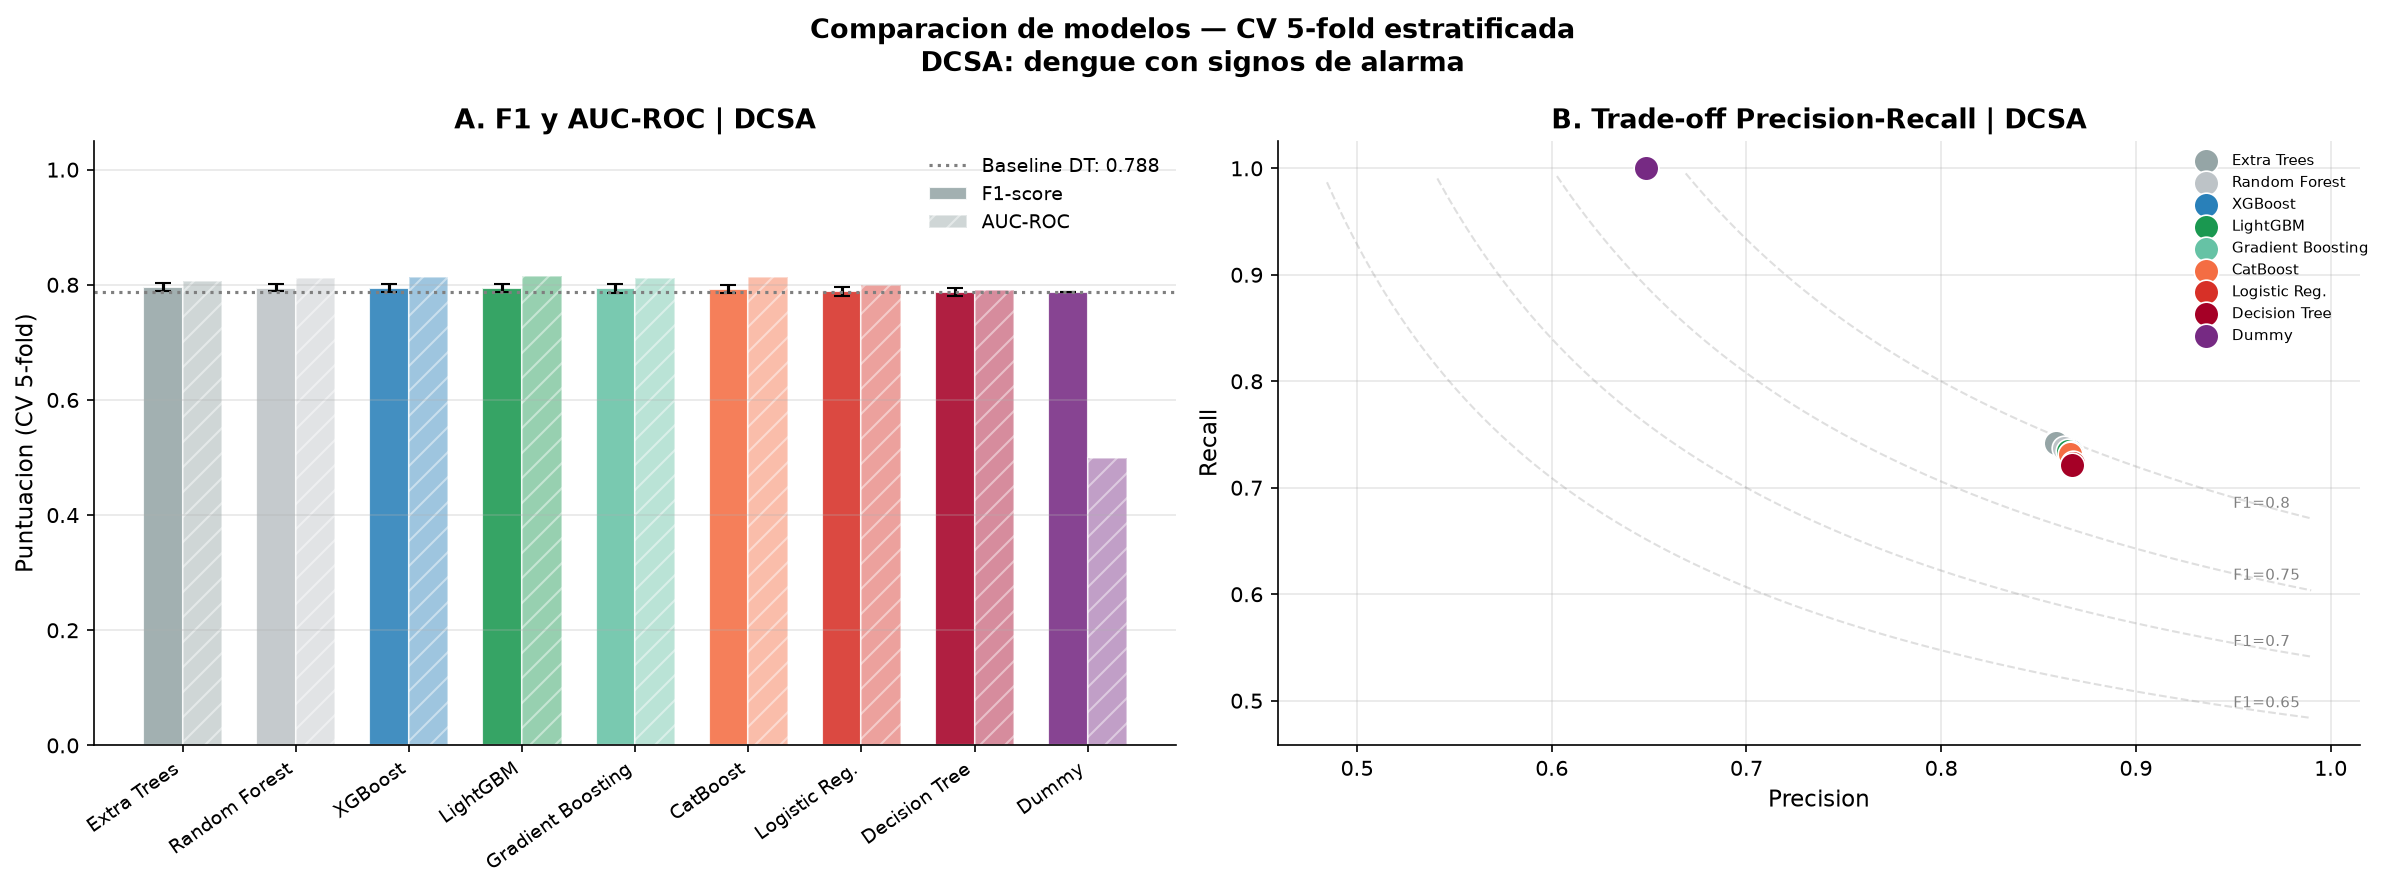

In [7]:
# Tabla resumen CV
filas = []
for nombre, res in resultados_cv.items():
    filas.append({
        'Modelo':    nombre,
        'F1':        round(res['f1']['mean'], 4),
        'F1_std':    round(res['f1']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('F1', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DCSA.csv', index=False)

# Grafico comparativo
colores_m = ['#95A5A6','#BDC3C7','#2980B9','#1A9850','#66C2A5',
             '#F46D43','#D73027','#A50026','#762A83']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
x  = np.arange(len(tabla_cv))
w  = 0.35
ax.bar(x - w/2, tabla_cv['F1'], w, yerr=tabla_cv['F1_std'],
    color=colores_m[:len(tabla_cv)], alpha=0.88, capsize=4,
    label='F1-score', edgecolor='white')
ax.bar(x + w/2, tabla_cv['AUC_ROC'], w,
    color=colores_m[:len(tabla_cv)], alpha=0.45, capsize=4,
    label='AUC-ROC', edgecolor='white', hatch='//')
# Linea de umbral baseline (Decision Tree)
dt_f1 = tabla_cv[tabla_cv['Modelo']=='Decision Tree']['F1'].values
if len(dt_f1):
    ax.axhline(dt_f1[0], color=COLORS['neutral'], linestyle=':',
        linewidth=1.5, label=f'Baseline DT: {dt_f1[0]:.3f}')
ax.set_xticks(x)
ax.set_xticklabels(tabla_cv['Modelo'], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Puntuacion (CV 5-fold)')
ax.set_title('A. F1 y AUC-ROC | DCSA')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
for i, (_, row) in enumerate(tabla_cv.iterrows()):
    ax.scatter(row['Precision'], row['Recall'], s=140,
        color=colores_m[i], zorder=5,
        edgecolors='white', linewidth=0.8, label=row['Modelo'])
prec_r = np.linspace(0.05, 0.99, 200)
for f1_val in [0.65, 0.70, 0.75, 0.80]:
    rec_r = (f1_val * prec_r) / (2 * prec_r - f1_val)
    mask  = (rec_r > 0) & (rec_r < 1)
    ax.plot(prec_r[mask], rec_r[mask], '--', alpha=0.25, color='gray', linewidth=1)
    if mask.sum() > 0:
        ax.text(prec_r[mask][-1]-0.04, rec_r[mask][-1]+0.01,
            f'F1={f1_val}', fontsize=7, color='gray')
ax.set_xlabel('Precision')
ax.set_ylabel('Recall')
ax.set_title('B. Trade-off Precision-Recall | DCSA')
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.3)

plt.suptitle('Comparacion de modelos — CV 5-fold estratificada\nDCSA: dengue con signos de alarma',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_cv_comparacion.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 5. Evaluación final en test set

Los 3 mejores modelos (excluyendo baselines) se reentrenan
sobre el 100% de train y se evalúan **una única vez** aquí.

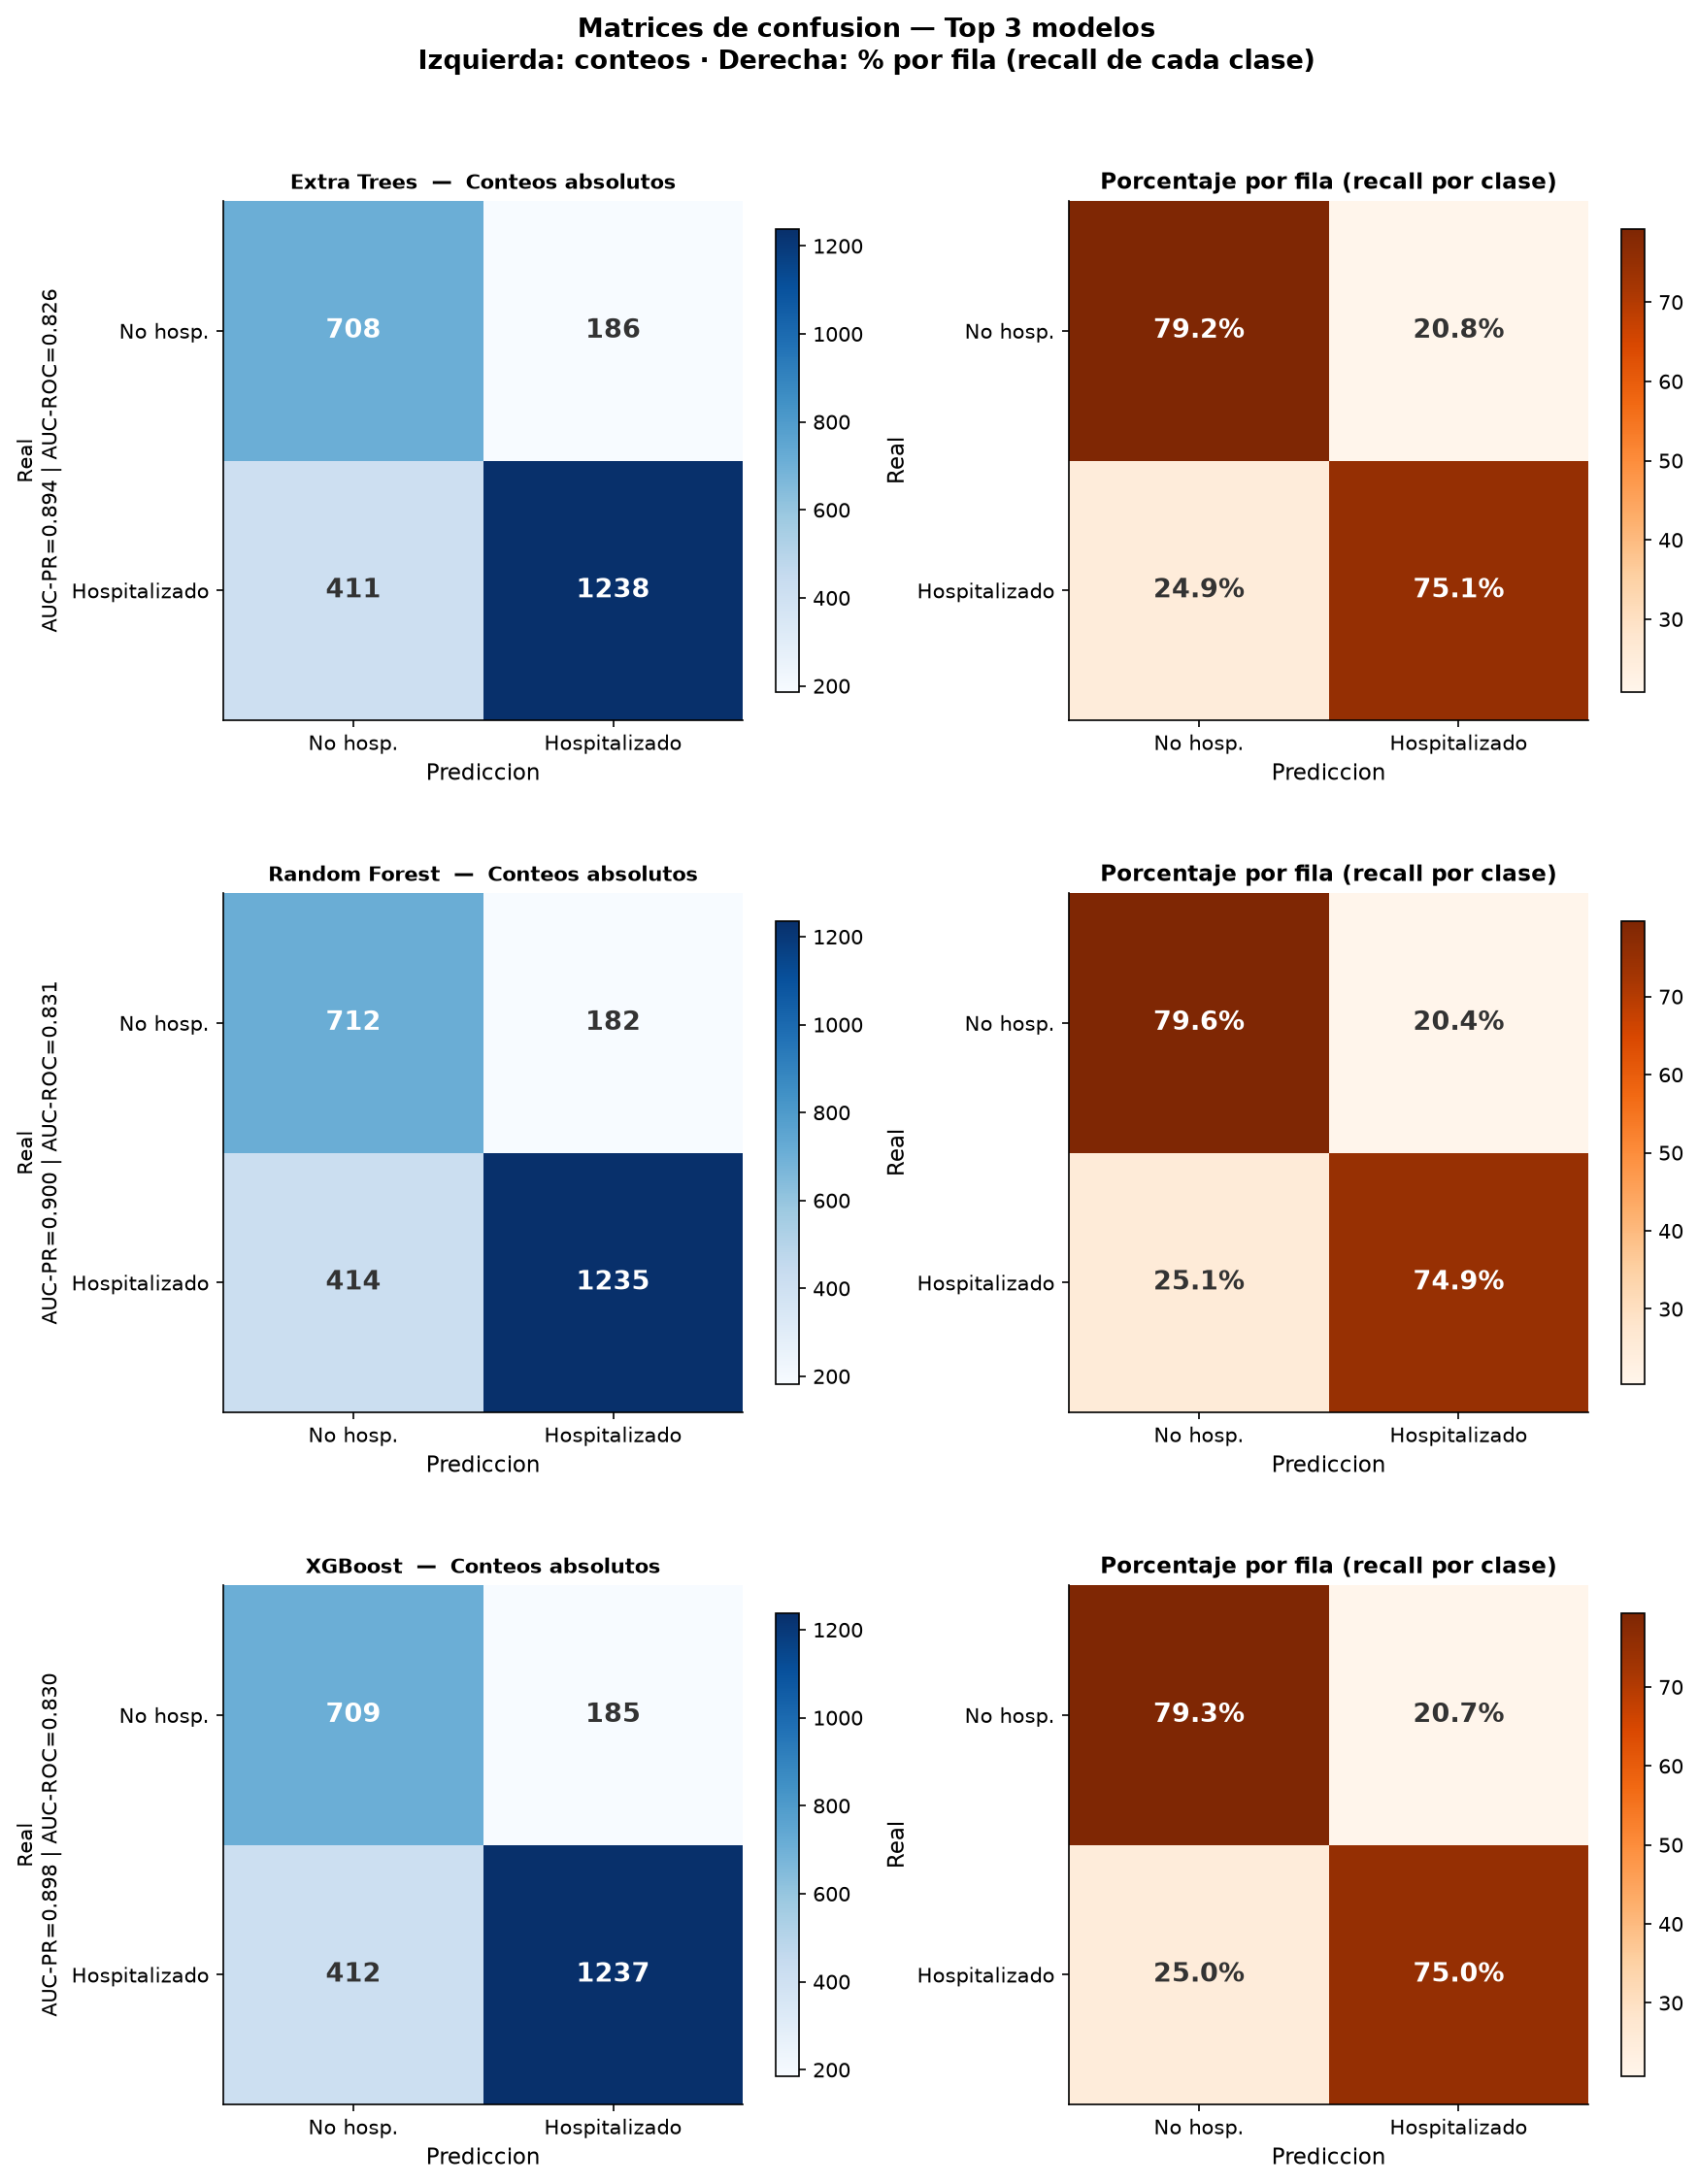

In [10]:
from sklearn.metrics import confusion_matrix
import matplotlib.patches as mpatches

def plot_confusion_matrix_dual(y_true, y_pred, y_prob, titulo, ax_row):
    """
    Dibuja dos matrices de confusion lado a lado:
    - Izquierda : conteos absolutos
    - Derecha   : porcentajes por fila (sensibilidad / especificidad)
    """
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    etiquetas   = ['No hosp.', 'Hospitalizado']
    n_clases    = len(etiquetas)
    cmap_abs    = plt.cm.Blues
    cmap_pct    = plt.cm.Oranges

    for ax, datos, fmt, cmap, subtitulo in zip(
        ax_row,
        [cm,       cm_pct],
        ['{:.0f}', '{:.1f}%'],
        [cmap_abs, cmap_pct],
        ['Conteos absolutos', 'Porcentaje por fila (recall por clase)']
    ):
        im = ax.imshow(datos, interpolation='nearest', cmap=cmap)
        plt.colorbar(im, ax=ax, shrink=0.8)

        thresh = datos.max() / 2
        for i in range(n_clases):
            for j in range(n_clases):
                color = 'white' if datos[i, j] > thresh else '#333333'
                ax.text(j, i, fmt.format(datos[i, j]),
                    ha='center', va='center',
                    fontsize=13, fontweight='bold', color=color)

        ax.set_xticks(range(n_clases))
        ax.set_yticks(range(n_clases))
        ax.set_xticklabels(etiquetas, fontsize=10)
        ax.set_yticklabels(etiquetas, fontsize=10)
        ax.set_xlabel('Prediccion', fontsize=11)
        ax.set_ylabel('Real', fontsize=11)
        ax.set_title(subtitulo, fontsize=11, fontweight='bold')

    # AUC-PR en el titulo del grupo
    auc_pr = average_precision_score(y_true, y_prob)
    auc_roc = roc_auc_score(y_true, y_prob)
    ax_row[0].set_ylabel(
        f'Real\nAUC-PR={auc_pr:.3f} | AUC-ROC={auc_roc:.3f}',
        fontsize=10)


# ── Grafico para los top 3 modelos ───────────────────────────────────────────
n_modelos = len(entrenados)
fig, axes = plt.subplots(n_modelos, 2, figsize=(12, 5 * n_modelos))

if n_modelos == 1:
    axes = [axes]  # asegurar iterable

for ax_row, (nombre, res) in zip(axes, entrenados.items()):
    plot_confusion_matrix_dual(
        y_test, res['y_pred'], res['y_prob'],
        titulo=nombre, ax_row=ax_row)
    ax_row[0].set_title(
        f'{nombre}  —  {ax_row[0].get_title()}',
        fontsize=10, fontweight='bold')

plt.suptitle(
    f'Matrices de confusion — Top {n_modelos} modelos\n'
    'Izquierda: conteos · Derecha: % por fila (recall de cada clase)',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / 'confusion_dual.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

,Modelo,F1,F1_std,AUC_ROC,AUC_PR,Bal_Acc,Precision,Recall
4,Extra Trees,0.7962,0.0073,0.8070,0.8781,0.7585,0.8588,0.7421
3,Random Forest,0.7953,0.0064,0.8118,0.8824,0.7607,0.8629,0.7375
6,XGBoost,0.7949,0.0069,0.8141,0.8840,0.7628,0.8665,0.7342
7,LightGBM,0.7947,0.0072,0.8150,0.8847,0.7618,0.8652,0.7348
5,Gradient Boosting,0.7942,0.0078,0.8117,0.8816,0.7625,0.8667,0.7328
8,CatBoost,0.7933,0.0070,0.8129,0.8829,0.7618,0.8664,0.7316
2,Logistic Reg.,0.7888,0.0081,0.7996,0.8737,0.7599,0.8678,0.7231
1,Decision Tree,0.7877,0.0072,0.7908,0.8442,0.7588,0.8672,0.7216
0,Dummy,0.7868,0.0000,0.5000,0.6485,0.5000,0.6485,1.0000


Top 3 por F1-CV: ['Extra Trees', 'Random Forest', 'XGBoost']
  Entrenando Extra Trees (parametros completos)...
    F1=0.8057 AUC=0.8261
  Memoria liberada
  RAM en uso: 337 MB
  Entrenando Random Forest (parametros completos)...
    F1=0.8056 AUC=0.8310
  Memoria liberada
  RAM en uso: 353 MB
  Entrenando XGBoost (parametros completos)...
    F1=0.8056 AUC=0.8297
  Memoria liberada
  RAM en uso: 359 MB
  Guardado evaluacion final DCSA: eval_test_DCSA.pkl (30.8 MB)


,Modelo,F1,AUC_ROC,AUC_PR,Precision,Recall,Bal_Acc
0,Extra Trees,0.8057,0.8261,0.8936,0.8694,0.7508,0.7714
1,Random Forest,0.8056,0.8310,0.9000,0.8716,0.7489,0.7727
2,XGBoost,0.8056,0.8297,0.8981,0.8699,0.7502,0.7716


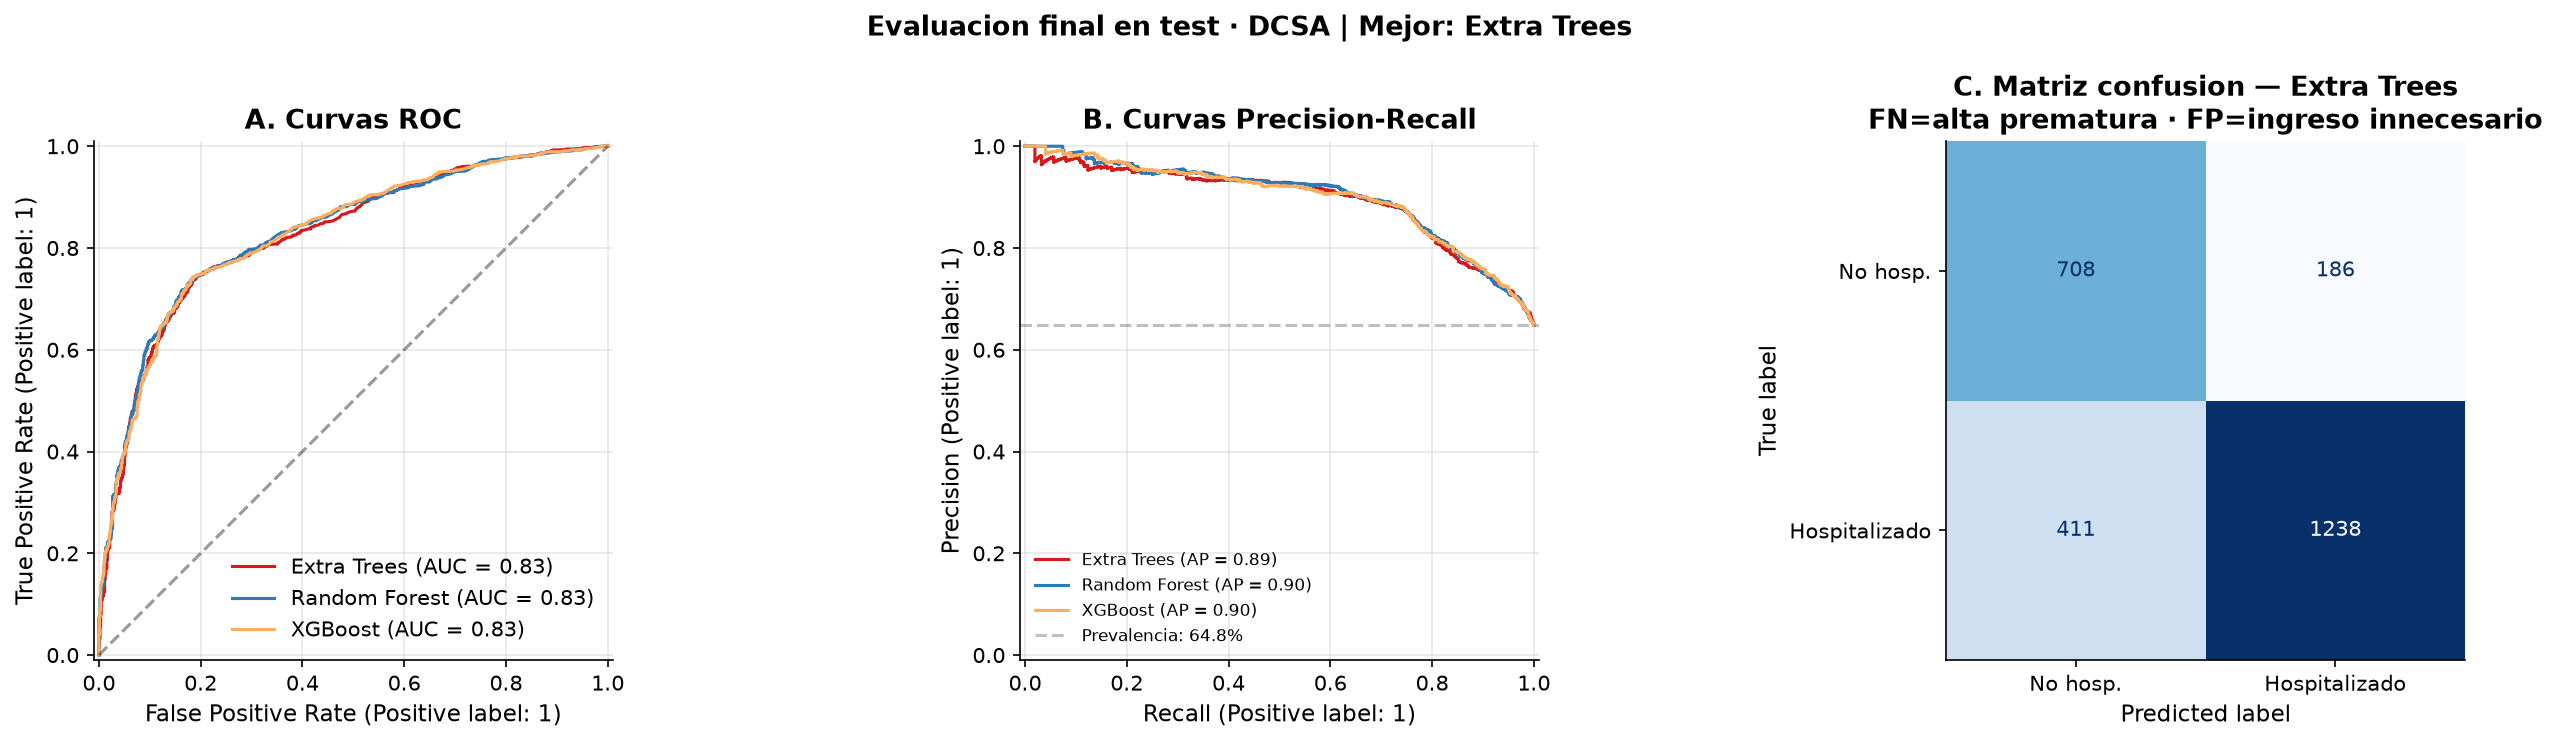

  RAM en uso: 369 MB


In [8]:
CP_EVAL = CHECKPOINTS / 'eval_test_DCSA.pkl'

filas = []
for nombre, res in resultados_cv.items():
    filas.append({'Modelo': nombre,
        'F1':        round(res['f1']['mean'], 4),
        'F1_std':    round(res['f1']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('F1', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DCSA.csv', index=False)

if checkpoint_existe(CP_EVAL):
    print('Evaluacion final ya calculada — cargando...')
    saved = joblib.load(CP_EVAL)
    tabla_test = saved['tabla_test']
    entrenados = saved['entrenados']
    mejor      = saved['mejor']
    display(tabla_test)
else:
    top3 = (tabla_cv[~tabla_cv['Modelo'].isin(['Dummy','Decision Tree'])]
        .head(3)['Modelo'].tolist())
    print(f'Top 3 por F1-CV: {top3}')
    entrenados, res_test = {}, []
    for nombre in top3:
        # Usar portafolio_final (n_estimators completos)
        pipe = portafolio_final[nombre]
        print(f'  Entrenando {nombre} (parametros completos)...')
        pipe.fit(X_train, y_train)
        y_prob = pipe.predict_proba(X_test)[:, 1]
        y_pred = pipe.predict(X_test)
        res_test.append({
            'Modelo':    nombre,
            'F1':        round(f1_score(y_test, y_pred), 4),
            'AUC_ROC':   round(roc_auc_score(y_test, y_prob), 4),
            'AUC_PR':    round(average_precision_score(y_test, y_prob), 4),
            'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
            'Recall':    round(recall_score(y_test, y_pred), 4),
            'Bal_Acc':   round(balanced_accuracy_score(y_test, y_pred), 4),
        })
        entrenados[nombre] = {'pipe': pipe, 'y_prob': y_prob, 'y_pred': y_pred}
        print(f'    F1={res_test[-1]["F1"]:.4f} AUC={res_test[-1]["AUC_ROC"]:.4f}')
        limpiar_memoria()
        memoria_usada()
    tabla_test = pd.DataFrame(res_test).sort_values('F1', ascending=False)
    mejor      = tabla_test.iloc[0]['Modelo']
    guardar_checkpoint({'tabla_test': tabla_test,
        'entrenados': entrenados, 'mejor': mejor},
        CP_EVAL, 'evaluacion final DCSA')
    display(tabla_test)
    tabla_test.to_csv(OUT_TAB / 'test_DCSA.csv', index=False)

colores_top = [COLORS['secondary'], COLORS['primary'], COLORS['accent']]
fig, axes   = plt.subplots(1, 3, figsize=(18, 5))
for i, (nombre, res) in enumerate(entrenados.items()):
    RocCurveDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre, color=colores_top[i], ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre, color=colores_top[i], ax=axes[1])
axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
axes[0].set_title('A. Curvas ROC'); axes[0].grid(alpha=0.3)
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', alpha=0.5,
    label=f'Prevalencia: {y_test.mean():.1%}')
axes[1].set_title('B. Curvas Precision-Recall')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
ConfusionMatrixDisplay.from_predictions(
    y_test, entrenados[mejor]['y_pred'],
    display_labels=['No hosp.', 'Hospitalizado'],
    cmap='Blues', ax=axes[2], colorbar=False)
axes[2].set_title(
    f'C. Matriz confusion — {mejor}\nFN=alta prematura · FP=ingreso innecesario')
plt.suptitle(f'Evaluacion final en test · DCSA | Mejor: {mejor}',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_evaluacion_test.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
memoria_usada()

## 6. Importancia de variables

In [ ]:
CP_IMP = CHECKPOINTS / 'importancia_DCSA.pkl'

vars_demograficas = ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']

if checkpoint_existe(CP_IMP):
    print('Importancia ya calculada — cargando checkpoint...')
    df_imp = joblib.load(CP_IMP)
else:
    pipe_m = entrenados[mejor]['pipe']
    print(f'Calculando permutation importance: {mejor} (n_repeats=20)...')
    perm = permutation_importance(
        pipe_m, X_test, y_test,
        n_repeats=20, random_state=RANDOM_STATE,
        scoring='f1', n_jobs=1)
    df_imp = pd.DataFrame({
        'Variable':    FEATURES,
        'Importancia': perm.importances_mean,
        'Std':         perm.importances_std,
    }).sort_values('Importancia', ascending=False)
    df_imp['Tipo'] = [
        'Signo de alarma'  if v in SIGNOS_ALARMA
        else ('Sintoma general' if v in SINTOMAS_GENERALES
        else ('Demografica'     if v in vars_demograficas
        else  'Estacionalidad'))   # SEMANA
        for v in df_imp['Variable']
    ]
    guardar_checkpoint(df_imp, CP_IMP, 'importancia')
    limpiar_memoria(perm)

# Excluir AÑO por si quedara en un checkpoint previo
df_imp = df_imp[df_imp['Variable'] != 'AÑO'].copy()

color_tipo = {
    'Signo de alarma': COLORS['con_signos'],
    'Sintoma general': COLORS['sin_signos'],
    'Demografica':     COLORS['accent'],
    'Estacionalidad':  COLORS['neutral'],
}

df_top    = df_imp.head(15)
colores_b = [color_tipo[t] for t in df_top['Tipo']]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    df_top['Variable'][::-1],
    df_top['Importancia'][::-1],
    xerr=df_top['Std'][::-1],
    color=colores_b[::-1],
    capsize=4, alpha=0.87, edgecolor='white', height=0.6
)

# Etiquetas de valor
for bar, (_, row) in zip(bars, df_top[::-1].iterrows()):
    ax.text(
        bar.get_width() + row['Std'] + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Importancia']:.4f}",
        va='center', fontsize=8, color='#444444'
    )

leyenda = [mpatches.Patch(color=c, label=t)
    for t, c in color_tipo.items()
    if t in df_top['Tipo'].values]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_xlabel('Reduccion en F1 al permutar (permutation importance)', fontsize=11)
ax.set_title(
    f'Importancia de variables — {mejor}\n'
    'Dengue con signos de alarma (DCSA) · n_repeats=20',
    fontsize=12, fontweight='bold')
ax.axvline(0, color=COLORS['neutral'], linewidth=0.8, alpha=0.5)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'con_signos_importancia.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Tabla resumen por tipo
print('\nImportancia promedio por tipo de variable:')
display(df_imp.groupby('Tipo')['Importancia']
    .agg(['mean','max','count']).round(4)
    .sort_values('mean', ascending=False))

df_imp.to_csv(OUT_TAB / 'importancia_DCSA.csv', index=False)
guardar_checkpoint({
    'modelo':    mejor,
    'pipeline':  entrenados[mejor]['pipe'],
    'features':  FEATURES,
    'tabla_test': tabla_test,
    'importancia': df_imp},
    CHECKPOINTS / 'mejor_modelo_DCSA.pkl', 'modelo final')
print(f'\nListo: {mejor}')
memoria_usada()

---

## Resumen DCSA

| Aspecto | Detalle |
|---------|--------|
| Cohorte | 12,713 casos · partición 80/20 estratificada |
| Metrica primaria | F1-score (desbalance moderado 65/35) |
| Baselines | Dummy + Decision Tree depth=3 |
| Tratamiento desbalance | SMOTE exclusivo sobre train |
| Evaluación final | Una única evaluación sobre test set |